In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib
matplotlib.rcParams['figure.figsize'] = (8, 5)

import warnings
warnings.filterwarnings('ignore')

# Boostings

Данные с которыми вы будете работать представляют из себя характеристики клиента страховой компании по которым нужно понять будет ли он заинтересован в страховке. Таким образом, страховая компания может более оптимально таргетить рекламу и выстраивать коммуникацию с клиентами, повышая конверсию.

**Описания колонок:**
- Gender - Male, Female
- Age - Возраст
- Driving_License - Наличие водительского удостоверения
- Region_Code - Область проживания
- Previously_Insured - Пользовался ли раньше услугами страховой компании
- Vehicle_Age - Возраст транспортного средства
- Vehicle_Damage - Попадало ли траспортное средство в ДТП
- Annual_Premium - Ежегодные выплаты клиента
- Policy_Sales_Channel - Политика распространения страховых услуг (через посредников, напрямую и т.д.)
- Vintage - Количество дней, в течение которых клиент был связан с компанией 


- **Response** - заинтересован в страховке 1, не откликнулся 0

In [12]:
data = pd.read_csv('vehicle_insurance.csv')

data

,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,Female,24,1,37.0,1,< 1 Year,No,21243.0,152.0,21,0
9996,Male,28,1,35.0,1,< 1 Year,No,23589.0,160.0,173,0
9997,Female,27,1,15.0,0,< 1 Year,Yes,33340.0,152.0,207,0
9998,Female,28,1,14.0,1,< 1 Year,No,25426.0,152.0,247,0


**Задание 0.** Проведите небольшой EDA. Посмотрите на распределения некоторых колонок, на матрицу корреляций. Также проверьте баланс классов и посмотрите на распределение возраста транспортного средства в зависимости от response. \
Закодируйте признаки типа `object` с помощью `one-hot` кодирования.

P.S. некоторые не `object`колонки по смыслу очевидно являются категориальными. Так как мы будем строить ансамбли на основе деревьев, их можно оставить в первоначальном виде.

In [13]:
### Your code is here
from category_encoders.one_hot import OneHotEncoder

object_cols = data.select_dtypes([object]).columns
object_df = data[object_cols]
ohe = OneHotEncoder()
ohe.fit(object_df)
object_df = ohe.transform(object_df)


data = pd.concat((data.drop(object_cols, axis=1), object_df), axis=1)
data.head()


,Age,Driving_License,Region_Code,Previously_Insured,Annual_Premium,Policy_Sales_Channel,Vintage,Response,Gender_1,Gender_2,Vehicle_Age_1,Vehicle_Age_2,Vehicle_Age_3,Vehicle_Damage_1,Vehicle_Damage_2
0,44,1,28.0,0,40454.0,26.0,217,1,1,0,1,0,0,1,0
1,76,1,3.0,0,33536.0,26.0,183,0,1,0,0,1,0,0,1
2,47,1,28.0,0,38294.0,26.0,27,1,1,0,1,0,0,1,0
3,21,1,11.0,1,28619.0,152.0,203,0,1,0,0,0,1,0,1
4,29,1,41.0,1,27496.0,152.0,39,0,0,1,0,0,1,0,1


<Axes: >

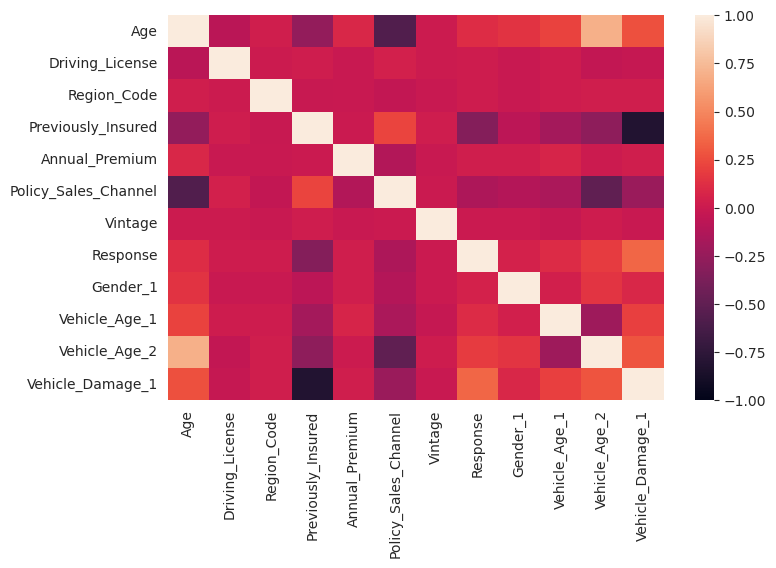

In [18]:


sns.heatmap(data.corr(),
           vmin=-1,
           vmax=1
           )



In [14]:
data = data.drop(['Gender_2', 'Vehicle_Age_3', 'Vehicle_Damage_2'], axis=1) 

**Задание 1.** Обучите градиентный бустинг из sklearn на данных и замерьте accuracy и f1-score на тестовой выборке. В качестве параметров ансамбля установите `learning_rate = 1`, `random_state = 1`, `n_estimators = 100`. Изобразите ROC-кривую и посчитайте AUC, оцените качество классификации. (2б)

P.S. для всех прочих моделей в этом домашнем задании тоже фиксируйте `random_state = 1`. Как думаете, что может быть случайного в процедуре обучения градиентного бустинга?

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, f1_score, roc_curve, auc

X = data.drop('Response', axis=1)
y = data['Response']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=0,
                                                    shuffle=True,
                                                    test_size=0.2)

In [16]:
from sklearn.ensemble import GradientBoostingClassifier

### Your code is here
model = GradientBoostingClassifier(learning_rate=1,
                                   n_estimators=100,
                                   random_state=1)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.90      0.94      0.92      1770
           1       0.26      0.17      0.20       230

    accuracy                           0.85      2000
   macro avg       0.58      0.55      0.56      2000
weighted avg       0.82      0.85      0.83      2000



In [17]:
fpr, tpr, thresholds = roc_curve(y_test, model.predict_proba(X_test)[:, 1])
print(round(auc(fpr, tpr), 3))

0.826


**Задание 2.** Переберите параметры `n_estimators` и `learning_rate` по двумерной сетке. При обучении в цикле сразу считайте f1-score на тестовой выборке и сохраняйте результат в матрицу. Для какого алгоритма качество окажется максимальным?

Постройте кривые для метрики f1-score в зависимости от числа шагов для нескольких learning_rate. Изобразите heatmap полученной матрицы. Сделайте вывод, как количество шагов влияет на качество совместно с различной скоростью обучения? (2б)

P.S. для подсчета f1-score передайте в функцию параметр `average='weighted'`, чтобы учитывался еще и баланс классов (вспомните микро/макро-усреднения).

In [20]:
### Задаем сетку параметров

n_estimators_list = [5, 10, 20, 50, 100, 200, 700, 1000]
learning_rate_list = [1, 0.1, 0.01]

In [21]:
### Your code is here
f1_matrix = np.zeros( ((len(n_estimators_list)), len(learning_rate_list)) )

# Пройдемся по значениям n_estimators
for (i, n) in enumerate(n_estimators_list):
    # Пройдемся по значениям learning_rate
    for (j, lr) in enumerate(learning_rate_list):
        
        # Инициализируем и обучим GradientBoostingClassifier
        gbc = GradientBoostingClassifier(learning_rate=lr, 
                                         n_estimators=n, 
                                         random_state=1,
                                         max_depth=5)
        gbc.fit(X_train, y_train)
        # Запишем предсказания на тесте
        y_pred = gbc.predict(X_test)
        # Поместим f1_score в матрицу
        f1_matrix[i, j] = f1_score(y_test, y_pred, average='weighted')

# Переведем матрицу в DataFrame
f1_df = pd.DataFrame(f1_matrix,
                    index=map(str, n_estimators_list),
                    columns=map(str, learning_rate_list))

f1_df



,1,0.1,0.01
5,0.838456,0.831971,0.831008
10,0.834592,0.831971,0.831008
20,0.840150,0.832916,0.831008
50,0.832853,0.832143,0.832224
100,0.834430,0.839358,0.831971
200,0.834081,0.844921,0.831717
700,0.830367,0.839371,0.834625
1000,0.828686,0.842347,0.837913


In [23]:
f1_df.max()

1       0.840150
0.1     0.844921
0.01    0.837913
dtype: float64

<Axes: >

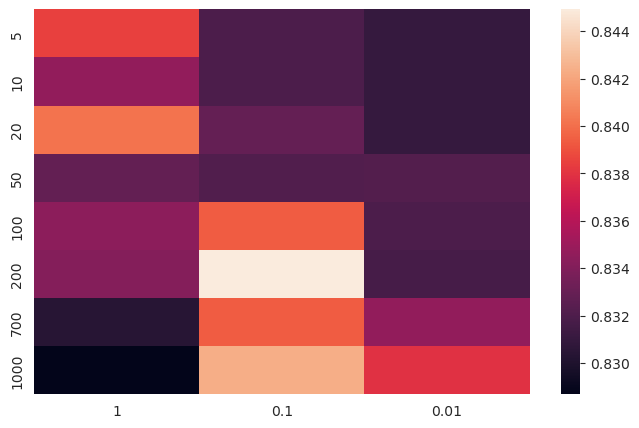

In [24]:


sns.heatmap(f1_df)



**Задание 3.** Вам потребуется обучить 4 модели и посчитать метрику f1-score на тестовой и обучающей выборках для каждой модели. 
1. Случайный лес с максимальной глубиной деревьев 5,
2. Случайный лес с максимальной глубиной деревьев 5000,
3. Градиентный бустинг с максимальной глубиной деревьев 5,
4. Градиентный бустинг с максимальной глубиной деревьев 5000.

Для каждой модели перебирайте значения `n_estimators`, как в предыдущем задании. Отрисуйте графики зависимости f1-score от количества шагов, используя `average='weighted'` для учёта баланса классов. 

Если в качестве базовой модели брать неглубокие деревья, то какая модель лучше запоминает обучающую выборку: случайный лес или градиентный бустинг? Какая из них лучше предсказывает на тестовой выборке? Как изменятся ответы, если базовая модель - это глубокое решающее дерево?

Подвержен ли переобучению случайный лес и градиентный бустинг? Как это отражается на графиках? (4б)

In [26]:
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

n_estimators_list = [2, 3, 4, 5, 10, 20, 50, 70, 100, 200, 700, 1000, 2000]

info_test = {}
info_train = {}

for n in n_estimators_list:
    rfc_5 = RandomForestClassifier(n_estimators=n, max_depth=5)
    rfc_5000 = RandomForestClassifier(n_estimators=n, max_depth=5000)
    gbc_5 = GradientBoostingClassifier(n_estimators=n, max_depth=5)
    gbc_5000 = GradientBoostingClassifier(n_estimators=n, max_depth=5000)
    for model in (rfc_5, rfc_5000, gbc_5, gbc_5000):
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        if model == rfc_5:
            info_test[f'rfc_5_{n}'] = f1_score(y_test, y_pred, average='weighted')
            info_train[f'rfc_5_{n}'] = f1_score(y_train, model.predict(X_train), average='weighted')
        elif model == rfc_5000:
            info_test[f'rfc_5K_{n}'] = f1_score(y_test, y_pred, average='weighted')
            info_train[f'rfc_5K_{n}'] = f1_score(y_train, model.predict(X_train), average='weighted')
        elif model == gbc_5:
            info_test[f'gbc_5_{n}'] = f1_score(y_test, y_pred, average='weighted')
            info_train[f'gbc_5_{n}'] = f1_score(y_train, model.predict(X_train), average='weighted')
        else:
            info_test[f'gbc_5K_{n}'] = f1_score(y_test, y_pred, average='weighted')
            info_train[f'gbc_5K_{n}'] = f1_score(y_train, model.predict(X_train), average='weighted')

In [27]:


rfc_5_test_scores = [info_test[f'rfc_5_{n}'] for n in n_estimators_list]
rfc_5K_test_scores = [info_test[f'rfc_5K_{n}'] for n in n_estimators_list]
gbc_5_test_scores = [info_test[f'gbc_5_{n}'] for n in n_estimators_list]
gbc_5K_test_scores = [info_test[f'gbc_5K_{n}'] for n in n_estimators_list]

rfc_5_train_scores = [info_train[f'rfc_5_{n}'] for n in n_estimators_list]
rfc_5K_train_scores = [info_train[f'rfc_5K_{n}'] for n in n_estimators_list]
gbc_5_train_scores = [info_train[f'gbc_5_{n}'] for n in n_estimators_list]
gbc_5K_train_scores = [info_train[f'gbc_5K_{n}'] for n in n_estimators_list]

estimators = list(map(str, n_estimators_list))



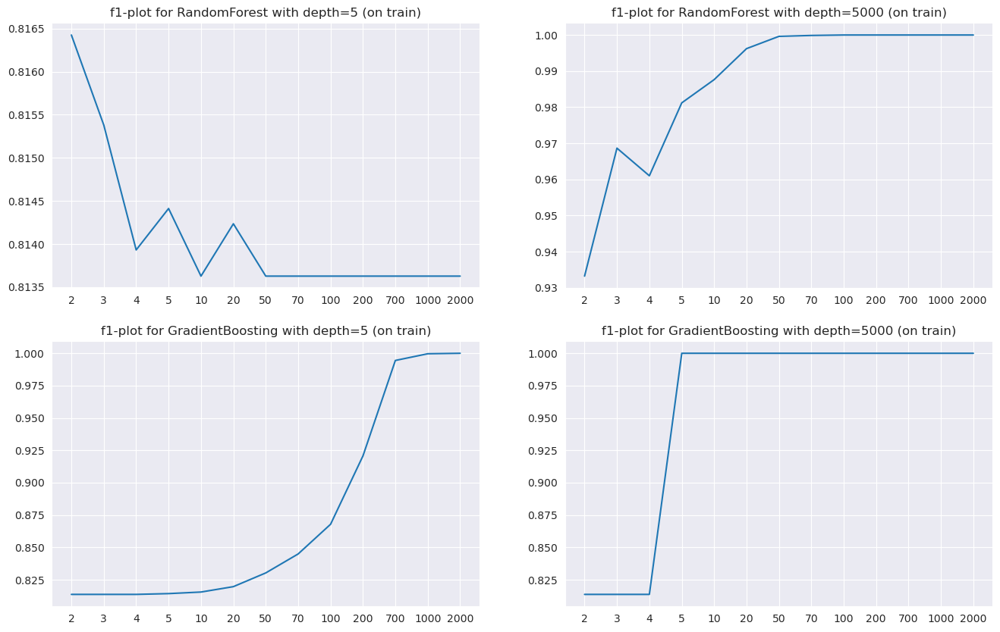

In [28]:
fig = plt.figure()
fig.set_size_inches(16, 10)

ax_1 = fig.add_subplot(2, 2, 1)
plt.plot(estimators, rfc_5_train_scores)
plt.title('f1-plot for RandomForest with depth=5 (on train)')

ax_2 = fig.add_subplot(2, 2, 2)
plt.plot(estimators, rfc_5K_train_scores)
plt.title('f1-plot for RandomForest with depth=5000 (on train)')


ax_3 = fig.add_subplot(2, 2, 3)
plt.plot(estimators, gbc_5_train_scores)
plt.title('f1-plot for GradientBoosting with depth=5 (on train)')


ax_4 = fig.add_subplot(2, 2, 4)
plt.plot(estimators, gbc_5K_train_scores)
plt.title('f1-plot for GradientBoosting with depth=5000 (on train)')
plt.show()

**Задание 4.** Установите библиотеку `catboost`. Главной особенностью catboost явялется наличие встроенной обработки категориальных признаков. Для каждого категориального столбца вычисляется следующее значение
$$
avg\_target = \dfrac{countInClass + prior}{totalCount + 1},
$$
* countInClass - количество объектов положительного класса для данной категории **до текущего объекта**,
* prior - некоторая константа для числителя, обычно равна доле положительного класса в таргете,
* totalCount - количество наблюдаемых категорий вплоть **до текущего** с той же категорией, что и у текущего.

Так как первые такие значения будут иметь больший разброс, чем последние, то выборку перемешивают несколько раз и полученные статистики усредняют. 
В отличие от target encoder подсчитанные значения зависят от наблюдаемой истории, т.е. вычисляются только из наблюдений до них, таким образом не происходит target leakage. 

Почитать подробнее можно здесь: [Transforming categorical features](https://catboost.ai/en/docs/concepts/algorithm-main-stages_cat-to-numberic)

Обучите CatBoostClassifier с дефолтными параметрами. Используйте датасет до  (разбейте на train/test по старой логике с тем же random state'ом). Категориальные колонки передайте в параметр `cat_features` метода `fit`. Catboost сам с ними разберется.

Сравните качество с моделью из предыдущего задания. Стало ли лучше?

Сравните feature importances в модели из задания 2 и в catboost с помощью соответствующих методов, изобразите их, используя `barplot`. \
Какие признаки стали более важными с новым методом кодирования? (4б)

In [29]:


from catboost import CatBoostClassifier

data_2 = pd.read_csv('vehicle_insurance.csv')

X = data_2.drop('Response', axis=1)
y = data_2['Response']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   random_state=0,
                                                   shuffle=True,
                                                   test_size=0.2)

cboost = CatBoostClassifier()
cboost.fit(X_train, y_train, cat_features=list(object_cols))


Learning rate set to 0.025035
0:	learn: 0.6524209	total: 55.6ms	remaining: 55.5s
1:	learn: 0.6213114	total: 62ms	remaining: 30.9s
2:	learn: 0.5922961	total: 67.8ms	remaining: 22.5s
3:	learn: 0.5658834	total: 72.6ms	remaining: 18.1s
4:	learn: 0.5423457	total: 77.5ms	remaining: 15.4s
5:	learn: 0.5180857	total: 83.5ms	remaining: 13.8s
6:	learn: 0.4986798	total: 89.3ms	remaining: 12.7s
7:	learn: 0.4802832	total: 94.8ms	remaining: 11.8s
8:	learn: 0.4619128	total: 102ms	remaining: 11.2s
9:	learn: 0.4465202	total: 107ms	remaining: 10.6s
10:	learn: 0.4341692	total: 122ms	remaining: 10.9s
11:	learn: 0.4204912	total: 126ms	remaining: 10.4s
12:	learn: 0.4147382	total: 131ms	remaining: 9.97s
13:	learn: 0.4094293	total: 136ms	remaining: 9.56s
14:	learn: 0.3996664	total: 140ms	remaining: 9.21s
15:	learn: 0.3902804	total: 145ms	remaining: 8.91s
16:	learn: 0.3851970	total: 150ms	remaining: 8.65s
17:	learn: 0.3768978	total: 154ms	remaining: 8.4s
18:	learn: 0.3694314	total: 158ms	remaining: 8.17s
19:	le

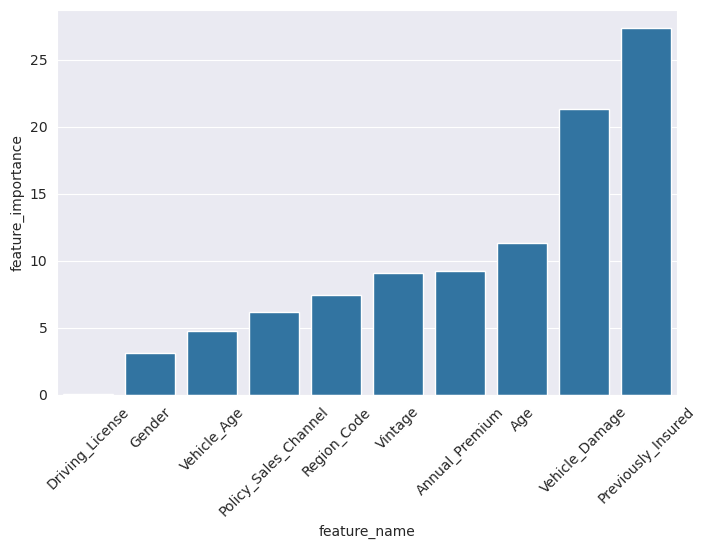

In [30]:
fi_df = pd.DataFrame({'feature_name': X.columns,
             'feature_importance': cboost.feature_importances_})

sns.barplot(y='feature_importance', x='feature_name', data=fi_df.sort_values('feature_importance'))
plt.xticks(rotation=45)
plt.show()


**Задание 5.** Установите библиотеку `lightgbm`. На сегодняшний день это наиболее быстрый метод градиентного бустинга, при этом расходующий небольшое количество оперативной памяти. Достигает он этого за счет построения деревьев вглубь по листьям (leaf-wise), а не по уровням (level-wise), как другие методы, например XGBoost. 
Более понятно это на картинке:

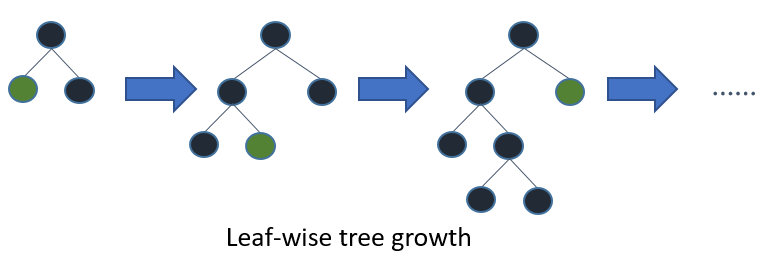

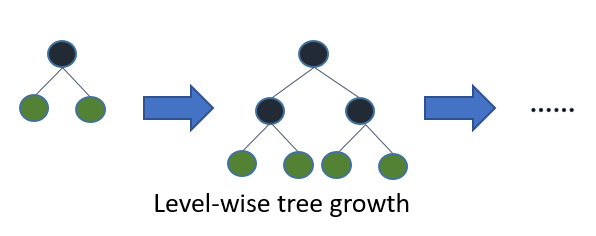

В то время, как XGBoost за раз разделяет вершины на целом уровне той же глубины, LightGBM разделяет одну вершину за раз. Отсюда прирост в скорости.

Обучите `LGBMClassifier` на изначальных(закодированных) данных и добейтесь максимального качества на тестовой выборке, перебрав параметры глубины деревьев, количества шагов, скорости обучения и т.д.

In [31]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import GridSearchCV

params = {'n_estimators': [100, 500, 1000, 2000],
          'max_depth': [2, 3, 5, 100],
          'learning_rate': [0.1, 0.01, 0.001]}

X = data.drop('Response', axis=1)
y = data['Response']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                   random_state=0,
                                                   shuffle=True,
                                                   test_size=0.2)


grid = GridSearchCV(LGBMClassifier(), param_grid=params)
grid.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 814, number of negative: 5586
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000369 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 678
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.127188 -> initscore=-1.926058
[LightGBM] [Info] Start training from score -1.926058
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

GridSearchCV(estimator=LGBMClassifier(),
             param_grid={'learning_rate': [0.1, 0.01, 0.001],
                         'max_depth': [2, 3, 5, 100],
                         'n_estimators': [100, 500, 1000, 2000]})

In [32]:


grid.best_params_



{'learning_rate': 0.01, 'max_depth': 2, 'n_estimators': 100}

In [33]:


model = LGBMClassifier(learning_rate=0.01, max_depth=2, n_estimators=100)
model.fit(X_train, y_train)
pd.DataFrame(classification_report(y_test, model.predict(X_test), output_dict=True))



[LightGBM] [Info] Number of positive: 1017, number of negative: 6983
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000119 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 681
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 10
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.127125 -> initscore=-1.926622
[LightGBM] [Info] Start training from score -1.926622
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -

,0,1,accuracy,macro avg,weighted avg
precision,0.885000,0.0,0.885,0.442500,0.783225
recall,1.000000,0.0,0.885,0.500000,0.885000
f1-score,0.938992,0.0,0.885,0.469496,0.831008
support,1770.000000,230.0,0.885,2000.000000,2000.000000
